# H3a: staranność bio odbiorcy a prawy swipe

Parametryzowany notebook (papermill). Logika: `src/rentfriends/h3a/`. Specyfikacja:
`docs/prompts/h3a-notebook-prompt.md`; decyzje: `docs/h3a/decision-log.md`.

**Prywatność:** notebook wyświetla i zapisuje wyłącznie agregaty (komórki < 5 użytkowników
wytłumione). Tekst bio, `user_key` ani wiersze tabel nie są nigdzie pokazywane.

Wnioski dotyczą **związku**, nie przyczynowości; match ≠ najem.

In [1]:
# Parameters (papermill)
RUN_LEVEL = 1
SAMPLE_FRAC = 1.0
SAMPLE_BY = "sender"
SEED = 20261102
MARGIN = 0.10
FIT_TIMEOUT_MIN = 90
REPORT_DIR = "reports/h3a"

In [2]:
# Parameters
RUN_LEVEL = 2
SAMPLE_FRAC = 1.0
REPORT_DIR = "reports/h3a"

In [3]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import pandas as pd

from rentfriends.h3a import analysis as A
from rentfriends.h3a.summary import write_summary

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
assert SAMPLE_BY == "sender", "only sender-level sampling is implemented"
ctx = A.setup(
    A.Params(
        run_level=RUN_LEVEL,
        sample_frac=SAMPLE_FRAC,
        sample_by=SAMPLE_BY,
        seed=SEED,
        margin=MARGIN,
        fit_timeout_min=FIT_TIMEOUT_MIN,
        report_dir=REPORT_DIR,
    )
)

## 1. Dane, reguła as-of (D7), przepływ próby (F0) i kontrola zgodności z kartą M1

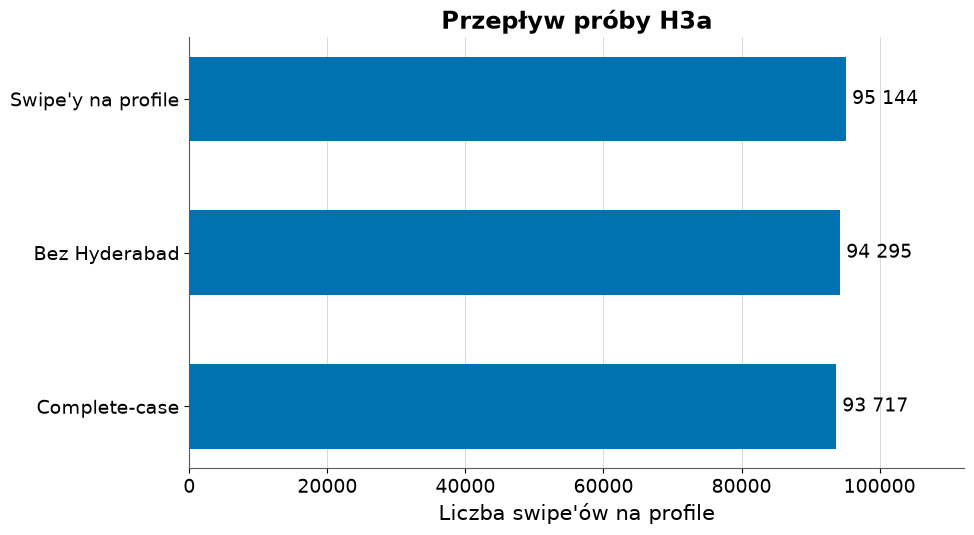

,krok,swipes,prawe,nadawcy,odbiorcy
0,Swipe'y na profile,95144,19495,1583,1394
1,Po wykluczeniu Hyderabad (nadawca lub odbiorca),94295,19363,1544,1363
2,Po complete-case (zmienne modelu),93717,19325,1538,1359


,miara,karta,asof,odchylenie_pct,bieżący_users,flaga_>1pct
0,profile_swipes,95144.00,95144.000,0.000,NaN,False
1,right_swipes,19495.00,19495.000,0.000,NaN,False
2,right_share_pct,20.49,20.490,-0.000,NaN,False
3,swipers,1583.00,1583.000,0.000,NaN,False
4,users,2065.00,2065.000,0.000,NaN,False
5,swipes_with_bio,52371.00,52297.000,-0.141,52371.000,False
6,right_pct_with_bio,21.50,21.420,-0.372,21.537,False
7,right_pct_without_bio,19.20,19.355,0.807,19.208,False
8,missing_age_band_swipes,578.00,578.000,0.000,NaN,False


Hyderabad: {'accounts': 45, 'accounts_any_version': 45, 'profile_swipes_removed': 849, 'as_sender': 669, 'as_receiver': 627}
Źródło wersji as-of: {'s': {'prior_version': 50932, 'first_version': 44086, 'users_current': 126}, 'r': {'prior_version': 88848, 'first_version': 5625, 'users_current': 671}, 'pair': {'prior_version': 47540, 'first_version': 46846, 'users_current': 758}}
G18 (bio_length vs tekst): {'receiver_snapshots': 2195, 'share_mismatch': 0.020045558086560365, 'share_swipes_mismatch': 0.025718910283359958}
Braki po filtrze Hyderabad: {'age_band_diff': 578, 'same_band': 578}


In [4]:
flow = A.prepare(ctx)
display(flow)
display(pd.DataFrame(ctx.res["card_check"]))
print("Hyderabad:", ctx.res["hyderabad"])
print("Źródło wersji as-of:", ctx.res["asof_source_counts"])
print("G18 (bio_length vs tekst):", ctx.res["g18_bio_length_mismatch"])
print("Braki po filtrze Hyderabad:", ctx.res["missing_by_var_after_hyd"])

## 2. Statystyki opisowe (F1, F2, F8)

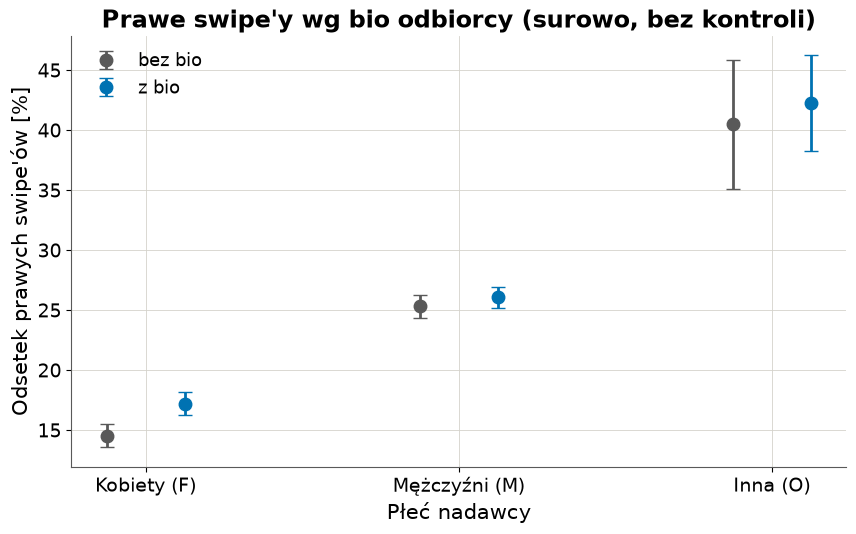

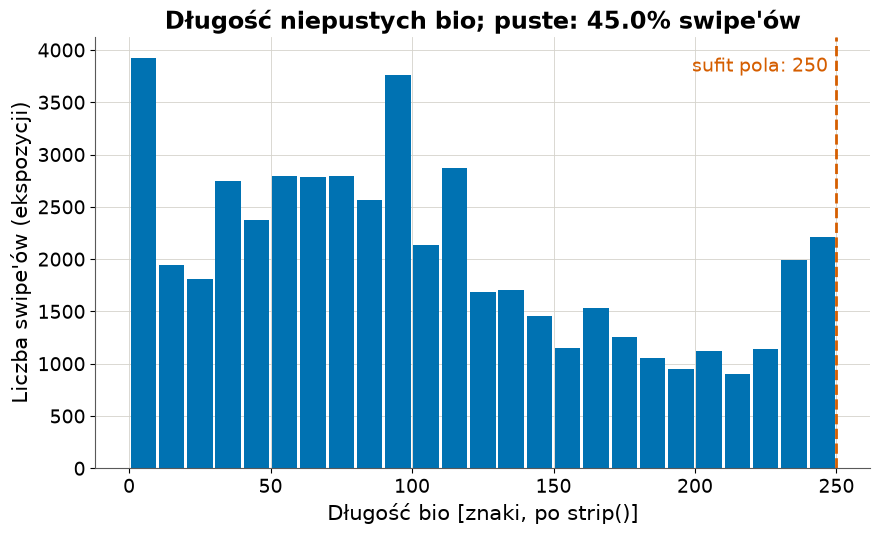

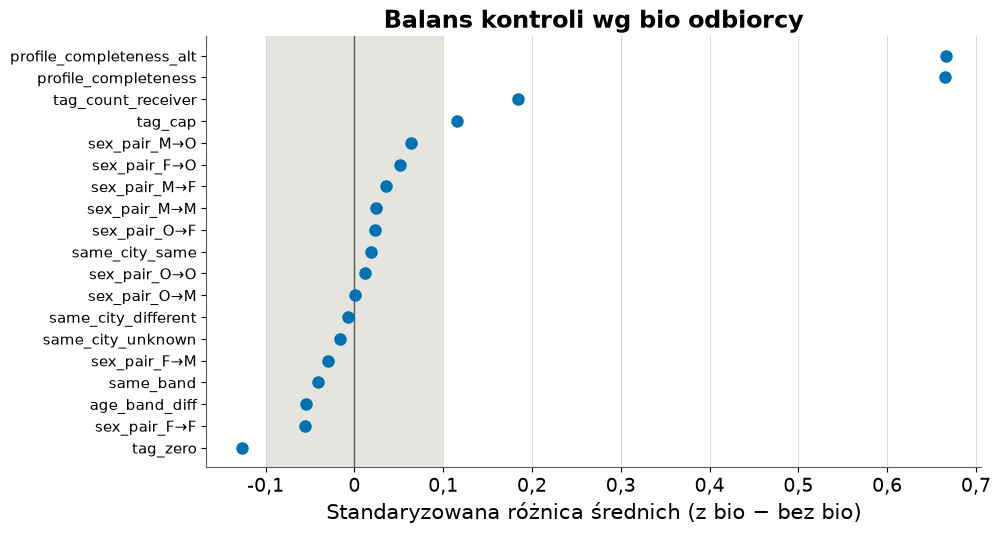

{'share_empty_swipes': np.float64(0.4498863599987195), 'share_cap_among_nonempty': 0.01737949762389681, 'bio_len_median_nonempty': 95.0, 'bio_len_iqr_nonempty': [50.0, 161.0]}


In [5]:
A.describe(ctx)
print(ctx.res["desc"])

## 3. Sanity check GLMM na danych symulowanych

Rzeczywisty design (X, nadawcy, odbiorcy), znane parametry: β_bio = 0,15, σ²_nadawca = 1,5,
σ²_odbiorca = 0,5. Estymator powinien je odtworzyć, a 95% CI pokrywać prawdę w ~95% powtórzeń.

In [6]:
A.sanity_check(ctx)

{'n_reps': 20,
 'n_ok': 12,
 'true_beta_bio': 0.15,
 'mean_beta_bio': 0.15946782022876246,
 'bias_beta_bio': 0.009467820228762469,
 'emp_sd_beta_bio': 0.05240716345188459,
 'mean_se_beta_bio': 0.04516109781386607,
 'coverage95_beta_bio': 0.9166666666666666,
 'true_var_sender': 1.5,
 'mean_var_sender': 1.4597092368449547,
 'true_var_receiver': 0.5,
 'mean_var_receiver': 0.5001974577153075,
 'mean_fit_s': 7.336773296197255,
 'optimizers': ["gradient_descent {'delta_rel_conv': 1e-08}",
  'lbfgs',
  "lbfgs {'delta_rel_conv': 1e-08}"]}

## 4. Modele główne M1 (GLMM), M2 (pooled logit, klastrowanie 2-kier.), M3 (FE nadawcy)
Etykieta według reguły z sekcji 7 promptu (ustalonej przed wynikami).

In [7]:
main_tab = A.main_models(ctx)
display(main_tab)
print(ctx.res["verdict"])
print(ctx.res["m1_diag"])
print(ctx.res["m3_diag"])

,model,status,beta,se,or,or_lo95,or_hi95,or_lo90,or_hi90,p,mde_or,label
0,M1,not_converged_or_no_se,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,brak oszacowania
1,M2,ok,0.122125,0.040187,1.129895,1.044313,1.222491,1.057622,1.207107,0.002374,1.119099,potwierdzony
2,M3,ok,0.172745,0.053581,1.188563,1.070074,1.320173,1.088294,1.298070,0.001264,1.161867,potwierdzony


{'label_M1': 'brak oszacowania', 'label_M2': 'potwierdzony', 'label_M3': 'potwierdzony', 'final': 'potwierdzony (fallback: M2 jako model główny, bez kontroli popularności)', 'lme4': 'pominięty (brak Rscript)', 'ame_M2': {'ame_pp': 1.9014251377286537, 'se_pp': 0.6155227818247532, 'lo95_pp': 0.6950226441722834, 'hi95_pp': 3.107827631285024}}
{'status': 'not_converged_or_no_se', 'optimizer': "lbfgs {'delta_rel_conv': 1e-08}", 'convergence_status': 2, 'n_iter': 27, 'time_s': 8.462459087371826, 'var_sender': 7.7698976897200325, 'var_receiver': 0.5592802217717461, 'var_sender_se': 0.4018941360371455, 'var_receiver_se': 0.03314457887706699, 'loglik': -27845.495884444972, 'attempts': [{'optimizer': 'lbfgs', 'convergence_status': 0, 'time_s': 6.481233358383179}, {'optimizer': 'gradient_descent', 'convergence_status': 0, 'time_s': 31.447845220565796}, {'optimizer': "gradient_descent {'delta_rel_conv': 1e-08}", 'convergence_status': 0, 'time_s': 52.702144622802734}, {'optimizer': "lbfgs {'delta_r

## 5. M5: długość bio (drugorzędne, bez werdyktu; F5)

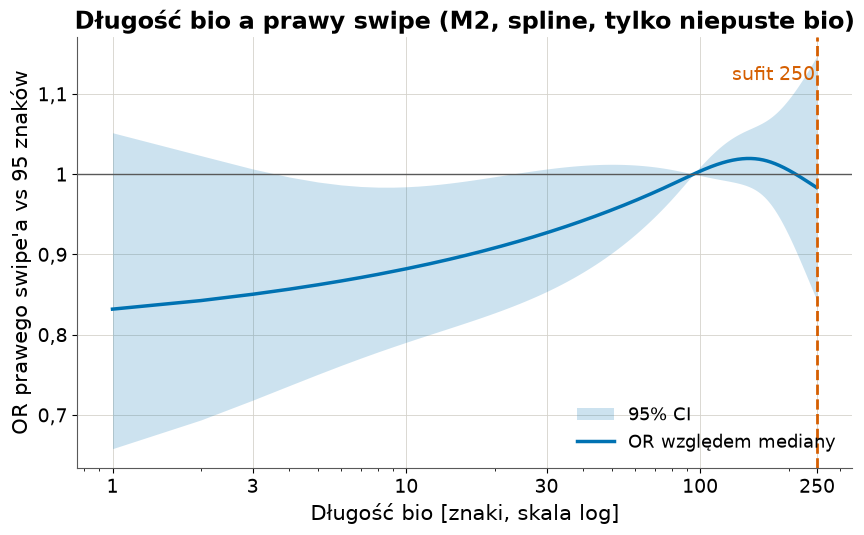

,model,beta_log1p_len,se,or_doubling,or_doubling_lo95,or_doubling_hi95,status,or_cap,or_cap_lo95,or_cap_hi95
0,M1,0.127468,NaN,1.092375,NaN,NaN,not_converged_or_no_se,0.942022,NaN,NaN
1,M2,0.044085,0.019438,1.031029,1.004159,1.058618,ok,0.912061,0.689186,1.207012


In [8]:
display(A.m5_length(ctx))

## 6. M6: przyrost predykcyjny (opisowy; F7)

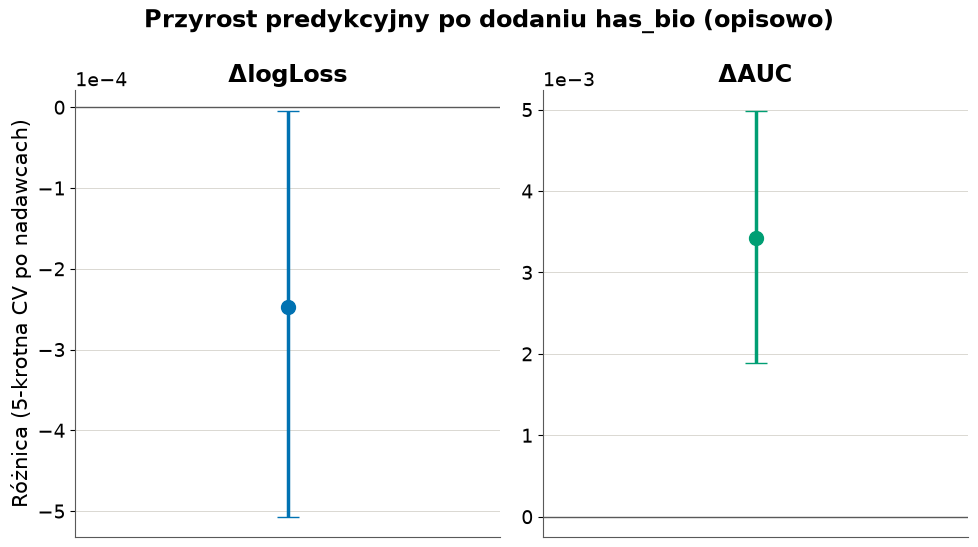

{'status': 'ok',
 'n_splits': 5,
 'n_boot': 1000,
 'logloss_base': 0.48846455871879096,
 'logloss_full': 0.48821782992778845,
 'auc_base': 0.6330933958874126,
 'auc_full': 0.6365218721093826,
 'd_logloss': -0.0002467287910025151,
 'd_logloss_lo95': -0.0005069151912649977,
 'd_logloss_hi95': -4.208206212134868e-06,
 'd_auc': 0.003428476221969956,
 'd_auc_lo95': 0.001887189041135301,
 'd_auc_hi95': 0.004987293913791978}

In [9]:
m6 = A.m6_predictive(ctx)
{k: v for k, v in m6.items() if not k.startswith("_")}

## 7. M4: analiza w obrębie odbiorcy z bramką wykonalności (F6)

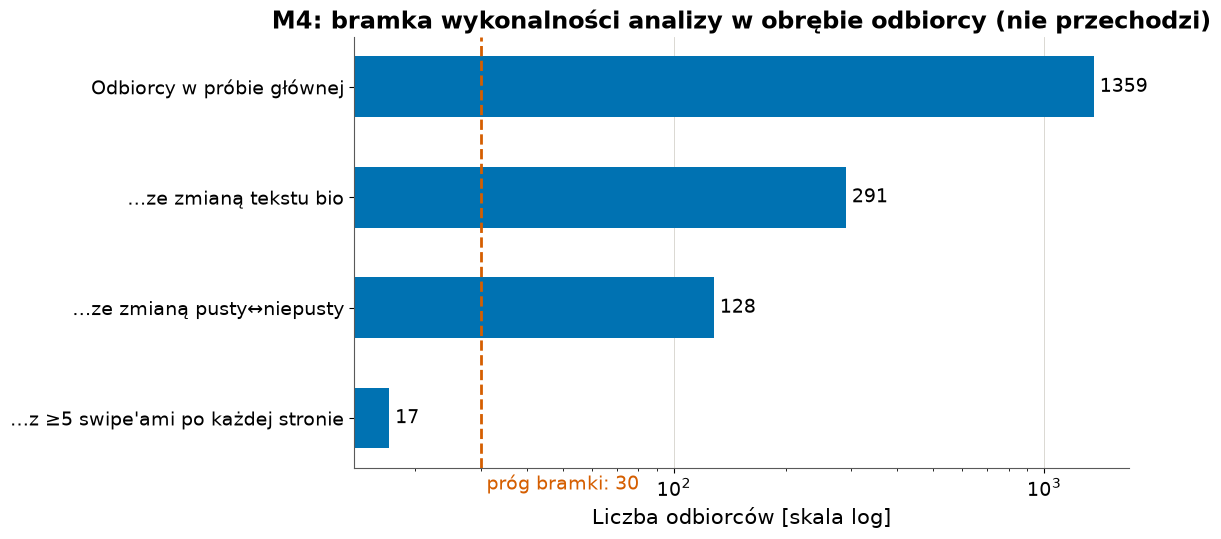

{'funnel': {'receivers_in_sample': 1359,
  'with_bio_text_change': 291,
  'with_status_change': 128,
  'swipes_on_status_changers': 11696,
  'swipes_after_exclusions': 10865,
  'swipes_eligible_receivers': 2179,
  'with_min_swipes_each_side': 17,
  'gate_threshold': 30,
  'gate_passed': False,
  'clean_only': False},
 'funnel_clean': {'receivers_in_sample': 1359,
  'with_bio_text_change': 291,
  'with_status_change': 65,
  'swipes_on_status_changers': 5927,
  'swipes_after_exclusions': 5476,
  'swipes_eligible_receivers': 1170,
  'with_min_swipes_each_side': 9,
  'gate_threshold': 30,
  'gate_passed': False,
  'clean_only': True},
 'verdict': 'niemożliwe do zmierzenia tym projektem: 17 odbiorców < 30'}

In [10]:
m4 = A.m4_within(ctx)
m4

## 8. Analizy wrażliwości S1-S8 (M2 i M3; na poziomie 2 także GLMM dla S1, S3, S4, S7; F4)

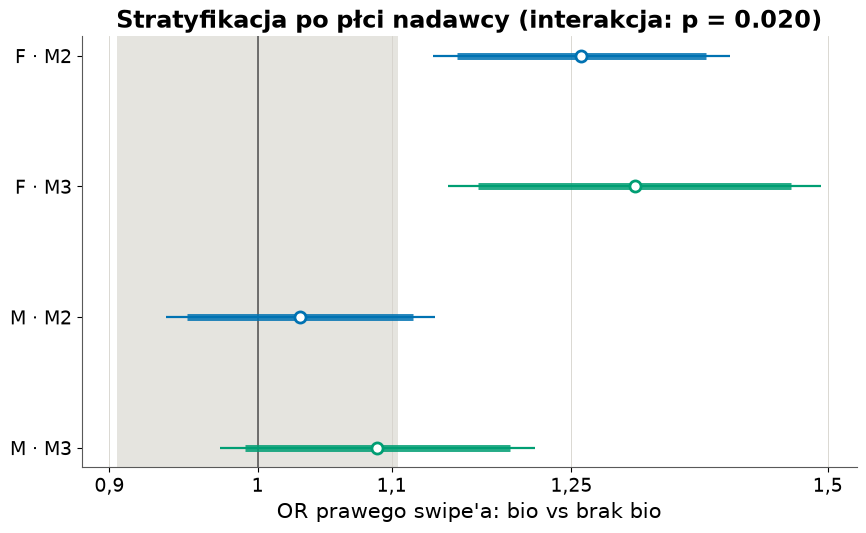

,spec,model,status,n_obs,n_receivers,beta,se,or,or_lo95,or_hi95,or_lo90,or_hi90,p,label
0,S1,M2,ok,76187,1273,0.129659,0.042934,1.138440,1.046560,1.238386,1.060815,1.221744,0.002528,potwierdzony
1,S1,M3,ok,76187,1273,0.173842,0.053818,1.189868,1.070751,1.322236,1.089064,1.300002,0.001237,potwierdzony
2,S2a,M2,ok,47373,1259,0.062101,0.046210,1.064070,0.971932,1.164942,0.986188,1.148102,0.178986,nierozstrzygający
3,S2a,M3,ok,47373,1259,0.160162,0.060746,1.173701,1.041959,1.322101,1.062096,1.297034,0.008374,potwierdzony
4,S2b,M2,ok,93717,1359,0.119265,0.039828,1.126669,1.042065,1.218142,1.055225,1.202950,0.002749,potwierdzony
5,S2b,M3,ok,93717,1359,0.158561,0.055450,1.171824,1.051146,1.306356,1.069674,1.283728,0.004243,potwierdzony
6,S3,M2,ok,94566,1390,0.120306,0.039918,1.127842,1.042965,1.219626,1.056167,1.204381,0.002580,potwierdzony
7,S3,M3,ok,94566,1390,0.171553,0.053335,1.187147,1.069315,1.317963,1.087438,1.295998,0.001298,potwierdzony
8,S4,M2,ok,93717,1359,0.122383,0.040247,1.130187,1.044460,1.222951,1.057790,1.207539,0.002360,potwierdzony
9,S4,M3,ok,93717,1359,0.172088,0.053577,1.187783,1.069381,1.319294,1.087588,1.297208,0.001318,potwierdzony


{'senders_main': 1538, 'senders_ge10': 1134, 'all_right_ge10': 15, 'all_left_ge10': 328, 'senders_kept': 791}
{'terms': ['has_bio:sender_sex=M', 'has_bio:sender_sex=O'], 'coef': [-0.18418900355795503, -0.10854758179858442], 'se': [0.06637274287019969, 0.18988734325491502], 'wald_chi2': 7.821730401806833, 'df': 2, 'p': 0.02002316950078277}


In [11]:
sens = A.sensitivity(ctx, level=1)
display(sens)
print(ctx.res["s1_counts"])
print(ctx.res["s8"]["interaction"])

## 9. Poziom 2: refity GLMM dla S1, S3, S4, S7 i cross-check lme4

[GPBoost] [Info] GPBoost is using 8 OpenMP threads by default for parallel computations. Run gpboost.tune_num_threads() to benchmark different numbers of threads and to select a tuned default for this session. For the best performance, try different values of 'num_parallel_threads' on the 'GPModel' you are using.
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated since its line search has not been successful. This can mean that no further progress is possible (the parameters are then essentially a local optimum) or that the optimizer has stopped prematu

[GPBoost] [Info] GPBoost is using 8 OpenMP threads by default for parallel computations. Run gpboost.tune_num_threads() to benchmark different numbers of threads and to select a tuned default for this session. For the best performance, try different values of 'num_parallel_threads' on the 'GPModel' you are using.
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated since its line search has not been successful. This can mean that no further progress is possible (the parameters are then essentially a local optimum) or that the optimizer has stopped prematu

[GPBoost] [Info] GPBoost is using 8 OpenMP threads by default for parallel computations. Run gpboost.tune_num_threads() to benchmark different numbers of threads and to select a tuned default for this session. For the best performance, try different values of 'num_parallel_threads' on the 'GPModel' you are using.
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 


[GPBoost] [Info] GPBoost is using 8 OpenMP threads by default for parallel computations. Run gpboost.tune_num_threads() to benchmark different numbers of threads and to select a tuned default for this session. For the best performance, try different values of 'num_parallel_threads' on the 'GPModel' you are using.
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 
[GPBoost] [Warning] Cannot calculate standard deviations for regression coefficients since the approximated Hessian is not positive definite 


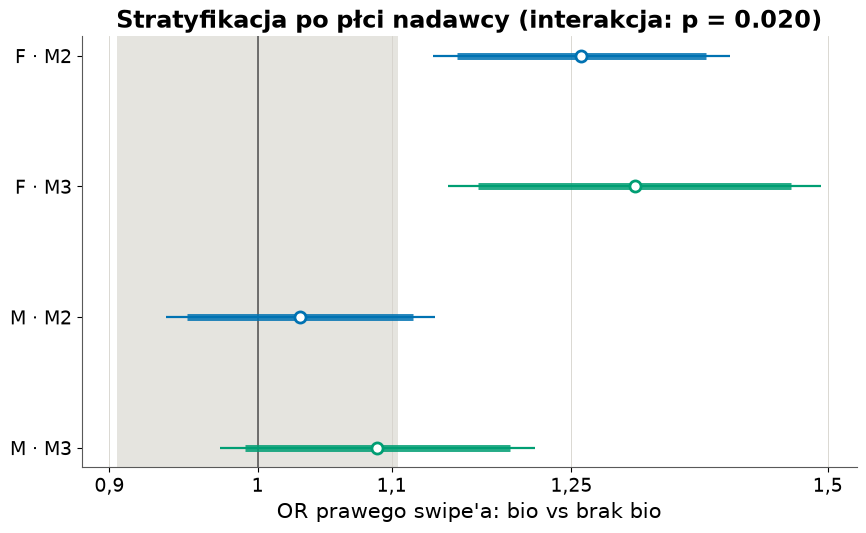

,spec,model,status,n_obs,n_receivers,beta,se,or,or_lo95,or_hi95,or_lo90,or_hi90,p,label
0,S1,M1,not_converged_or_no_se,76187,1273,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,brak oszacowania
7,S3,M1,not_converged_or_no_se,94566,1390,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,brak oszacowania
10,S4,M1,not_converged_or_no_se,93717,1359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,brak oszacowania
17,S7,M1,not_converged_or_no_se,93717,1359,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,brak oszacowania


{'status': 'skipped', 'reason': 'Rscript not found'}


In [12]:
if RUN_LEVEL >= 2:
    sens = A.sensitivity(ctx, level=2)
    display(sens[sens["model"] == "M1"])
print(A.lme4_crosscheck(ctx))

## 10. Wykres główny (F3) i podsumowanie

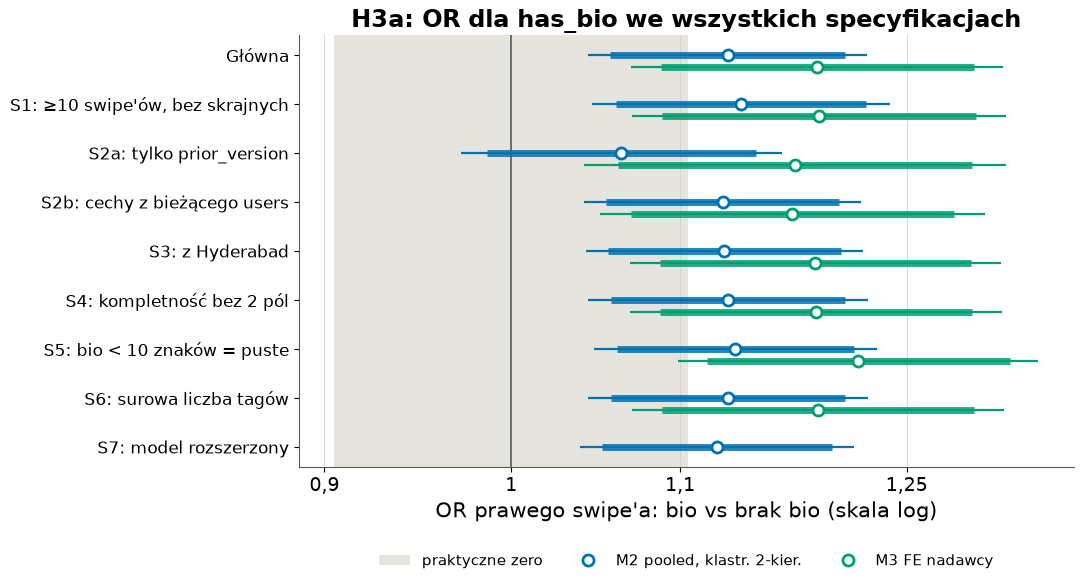

# H3a: wyniki (generowane automatycznie)

Wygenerowano: 2026-11-02T21:31; poziom przebiegu: 2; SAMPLE_FRAC = 1.0; SEED = 20261102; margines praktycznego zera |log OR| ≤ 0,10.

## Werdykt

**Etykieta końcowa: potwierdzony (fallback: M2 jako model główny, bez kontroli popularności)**

- M1 (GLMM, skrzyżowane efekty losowe): brak oszacowania
- M2 (pooled logit, klastrowanie dwukierunkowe): potwierdzony
- M3 (FE nadawcy, klastrowanie po odbiorcy; poza regułą): potwierdzony
- lme4: skipped (Rscript not found)

## Wynik główny (has_bio: bio odbiorcy niepuste vs puste)

| Model | OR (95% CI; 90% CI) | β | SE | p | MDE OR | Etykieta |
|---|---|---|---|---|---|---|
| M1 | – (95% CI –––; 90% CI –––) | – | – | – | – | brak oszacowania |
| M2 | 1,130 (95% CI 1,044–1,222; 90% CI 1,058–1,207) | 0,1221 | 0,0402 | 0,0024 | 1,119 | potwierdzony |
| M3 | 1,189 (95% CI 1,070–1,320; 90% CI 1,088–1,298) | 0,1727 | 0,0536 | 0,0013 | 1,162 | potwierdzony |

Średni efekt krańcowy (M2, populacyjny): 1,90 p.p. 

In [13]:
forest_df = A.forest(ctx)
path = write_summary(ctx.res, REPORT_DIR, RUN_LEVEL)
print(path.read_text())